# Paso 7 – Clustering **versión 3**: reducción MCA + numéricas estandarizadas (euclidiana)

**Dataset:** `Resultados_EnfoqueB/Dataset_final_enfoqueB.xlsx` (Paso 4B).

**Idea de esta versión:** en el Paso 4B se evaluó la reducción de dimensiones. El PCA no se justificó para las numéricas (KMO 0.51), pero el **MCA sí** para las cualitativas: 3 ejes recogen el 97 % de la inercia corregida de Benzécri. Esta versión usa **la misma información que la v1** (13 variables), con otra representación:
- las **8 variables cualitativas** pasan a **3 dimensiones MCA**;
- las **5 numéricas u ordinales** se estandarizan (media 0, desviación 1);
- y se agrupa con **distancia euclidiana**, lo que permite usar los modelos clásicos del curso: **K-Means**, **jerárquico de Ward** y **mezcla gaussiana (GMM)**.

La pregunta es si la reducción de dimensiones da grupos mejor separados o más estables que Gower sobre las variables originales.

Al final (sección 8) se **comparan las tres versiones**. La elección del modelo final se hace en el Paso 8, después de validar las cuatro versiones.

# 1. Librerías y datos

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)

VERSION = 'v3'
BASE = Path.cwd().parent if Path.cwd().name == 'Notebooks' else Path.cwd()
RUTA = BASE / 'Resultados_EnfoqueB'
X = pd.read_excel(RUTA / 'Dataset_final_enfoqueB.xlsx', sheet_name='dataset').set_index('id_persona')
versiones = pd.read_excel(RUTA / 'Dataset_final_enfoqueB.xlsx', sheet_name='versiones')
TIPOS = dict(versiones.loc[versiones['version'] == VERSION, ['variable', 'tipo_gower']].values)
CUALI = [c for c, t in TIPOS.items() if t in ('cat', 'bin')]
NUME = [c for c, t in TIPOS.items() if t in ('num', 'ord')]
N = len(X)
print(f'{N} NNA | cualitativas ({len(CUALI)}): {CUALI}')
print(f'numéricas/ordinales ({len(NUME)}): {NUME}')

161 NNA | cualitativas (8): ['sexo', 'procedencia_provincias', 'salud_fisica_cronica', 'presenta_discapacidad', 'flag_rezago_escolar', 'estado_pti', 'situacion_juridica', 'malnutricion_flag']
numéricas/ordinales (5): ['ln_permanencia', 'edad_modelo', 'nivel_atencion_salud_mental', 'score_imc', 'prop_meses_sin_pti_vigente']


# 2. Representación: MCA (cualitativas) + numéricas estandarizadas

In [2]:
def mca(df, cols):
    Z = pd.get_dummies(df[cols].astype(str), prefix_sep='=').astype(float)
    P = Z / Z.values.sum()
    r, c = P.sum(1).values, P.sum(0).values
    S = (P.values - np.outer(r, c)) / np.sqrt(np.outer(r, c))
    U, s, Vt = np.linalg.svd(S, full_matrices=False)
    return Z, s ** 2, (U * s) / np.sqrt(r)[:, None], Vt


Zd, eig, F, Vt = mca(X, CUALI)
Q = len(CUALI)
benz = np.where(eig > 1 / Q, ((Q / (Q - 1)) * (eig - 1 / Q)) ** 2, 0)
benz_acum = np.cumsum(benz) / benz.sum()
N_DIM = int(np.argmax(benz_acum >= 0.90) + 1)                    # dimensiones para superar el 90 % de la inercia corregida
print(f'Dimensiones MCA retenidas: {N_DIM} (inercia corregida acumulada = {benz_acum[N_DIM - 1] * 100:.1f} %)')

coords = pd.DataFrame(F[:, :N_DIM], index=X.index, columns=[f'MCA{i + 1}' for i in range(N_DIM)])
num_std = (X[NUME] - X[NUME].mean()) / X[NUME].std(ddof=0)
E_df = pd.concat([num_std, (coords - coords.mean()) / coords.std(ddof=0)], axis=1)   # todas las columnas con varianza 1
E = E_df.values
print('Matriz de trabajo:', E.shape)

contrib = pd.DataFrame((Vt[:N_DIM].T ** 2) * 100, index=Zd.columns, columns=coords.columns)
for d in coords.columns:
    print(f'\n{d} – categorías que más aportan (%):', contrib[d].sort_values(ascending=False).head(5).round(1).to_dict())

Dimensiones MCA retenidas: 3 (inercia corregida acumulada = 97.2 %)
Matriz de trabajo: (161, 8)

MCA1 – categorías que más aportan (%): {'flag_rezago_escolar=1': 19.9, 'presenta_discapacidad=1': 19.8, 'salud_fisica_cronica=1': 18.3, 'situacion_juridica=4 Sin definir / En observacion': 12.4, 'estado_pti=Sin PTI': 4.6}

MCA2 – categorías que más aportan (%): {'procedencia_provincias=1': 24.5, 'situacion_juridica=1 Tutela / Medida judicial firme': 21.4, 'estado_pti=Vencido': 14.0, 'situacion_juridica=3 Investigacion tutelar / Medida provisional': 8.4, 'flag_rezago_escolar=1': 7.6}

MCA3 – categorías que más aportan (%): {'situacion_juridica=2 Acogimiento residencial formal': 14.3, 'situacion_juridica=4 Sin definir / En observacion': 13.0, 'sexo=F': 11.4, 'sexo=M': 9.2, 'malnutricion_flag=0': 9.0}


**Comentario 2:** la matriz de trabajo tiene **8 columnas**: 5 numéricas estandarizadas y 3 ejes del MCA, también estandarizados para que cada columna pese lo mismo en la distancia euclidiana. Hay que notar una consecuencia de esta representación: las 8 variables cualitativas quedan resumidas en 3 columnas, así que **pesan menos** que en Gower, donde cada variable cuenta 1/13. Eso es parte de lo que se evalúa.

# 3. Funciones de evaluación (las mismas reglas que v1 y v2)

Las métricas se calculan **en el espacio euclidiano de trabajo** y, para poder comparar con las versiones 1 y 2, la silueta también se calcula **sobre la matriz de Gower de las mismas 13 variables (v1)**. El criterio de k es el mismo: entre 3 y 7 grupos, mínimo 8 NNA por grupo, máximo índice combinado = silueta × ARI medio de estabilidad.

In [3]:
def gower(df, tipos):
    n = len(df)
    num, den = np.zeros((n, n)), np.zeros((n, n))
    for c, t in tipos.items():
        x = df[c]
        ok = np.asarray(x.notna())
        valid = ok[:, None] & ok[None, :]
        if t in ('num', 'ord'):
            v = np.asarray(x, dtype=float)
            rango = np.nanmax(v) - np.nanmin(v)
            d = np.abs(v[:, None] - v[None, :]) / rango if rango > 0 else np.zeros((n, n))
        else:
            v = np.asarray(x.astype(str), dtype=object)
            d = (v[:, None] != v[None, :]).astype(float)
        num += np.where(valid, d, 0)
        den += valid
    D = num / den
    np.fill_diagonal(D, 0)
    return D


def cramer_v(a, b):
    t = pd.crosstab(np.asarray(a), np.asarray(b))
    chi2 = chi2_contingency(t, correction=False)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))


def eta2(cat, num):
    d = pd.DataFrame({'c': np.asarray(cat), 'n': np.asarray(num, dtype=float)}).dropna()
    m = d['n'].mean()
    return d.groupby('c')['n'].apply(lambda s: len(s) * (s.mean() - m) ** 2).sum() / ((d['n'] - m) ** 2).sum()


D_gower = gower(X, TIPOS)
K_RANGO, K_CANDIDATOS, TAM_MIN = range(2, 9), range(3, 8), 8


def estabilidad(ajustar, k, B=100, frac=0.8, semilla=0):
    rng = np.random.default_rng(semilla)
    completa = ajustar(E, k)
    aris = []
    for _ in range(B):
        idx = np.sort(rng.choice(N, int(frac * N), replace=False))
        aris.append(adjusted_rand_score(completa[idx], ajustar(E[idx], k)))
    return np.mean(aris), np.std(aris)


def tabla_k(nombre, ajustar, extra=None):
    filas = []
    for k in K_RANGO:
        lab = ajustar(E, k)
        f = {'k': k, 'silueta_euclidiana': silhouette_score(E, lab), 'silueta_gower': silhouette_score(D_gower, lab, metric='precomputed'),
             'tamano_min': int(np.bincount(lab).min())}
        f['ARI_medio'], f['ARI_sd'] = estabilidad(ajustar, k)
        if extra:
            f.update(extra(k))
        filas.append(f)
    t = pd.DataFrame(filas).set_index('k')
    t['indice_combinado'] = t['silueta_euclidiana'] * t['ARI_medio']
    t['candidato'] = t.index.isin(K_CANDIDATOS) & (t['tamano_min'] >= TAM_MIN)
    t.insert(0, 'modelo', nombre)
    return t

# 4. Modelo 1 – K-Means

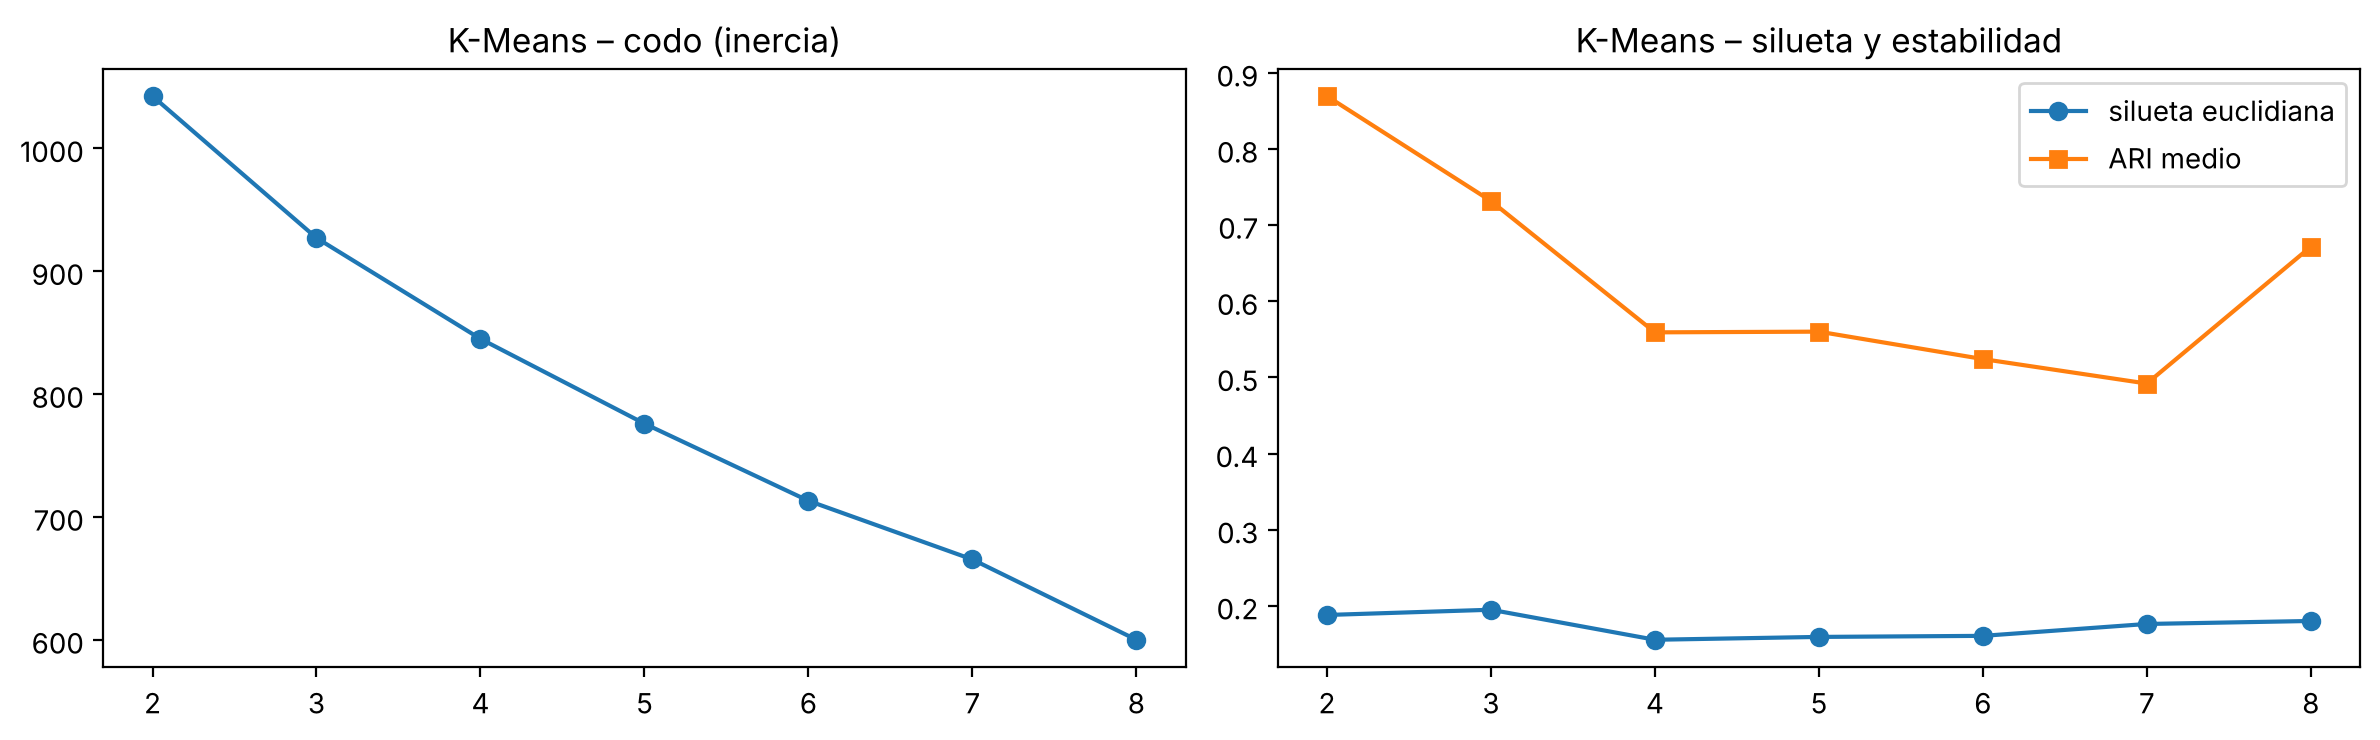

,modelo,silueta_euclidiana,silueta_gower,tamano_min,ARI_medio,ARI_sd,inercia,indice_combinado,candidato
k,,,,,,,,,
2,K-Means,0.188,0.148,73,0.869,0.100,1042.569,0.163,False
3,K-Means,0.195,0.139,23,0.732,0.163,927.144,0.143,True
4,K-Means,0.155,0.109,21,0.559,0.180,845.054,0.087,True
5,K-Means,0.159,0.112,19,0.560,0.116,776.053,0.089,True
6,K-Means,0.161,0.108,13,0.524,0.101,713.243,0.084,True
7,K-Means,0.176,0.116,3,0.492,0.117,665.498,0.087,False
8,K-Means,0.180,0.102,1,0.672,0.103,600.152,0.121,False


In [4]:
ajustar_km = lambda M, k: KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(M)
t_km = tabla_k('K-Means', ajustar_km, extra=lambda k: {'inercia': KMeans(n_clusters=k, n_init=20, random_state=42).fit(E).inertia_})
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(t_km.index, t_km['inercia'], marker='o')
ax[0].set_title('K-Means – codo (inercia)')
ax[1].plot(t_km.index, t_km['silueta_euclidiana'], marker='o', label='silueta euclidiana')
ax[1].plot(t_km.index, t_km['ARI_medio'], marker='s', label='ARI medio')
ax[1].legend()
ax[1].set_title('K-Means – silueta y estabilidad')
plt.tight_layout()
plt.show()
t_km.round(3)

# 5. Modelo 2 – Jerárquico de Ward

Ward sí es válido aquí, porque la distancia es euclidiana.

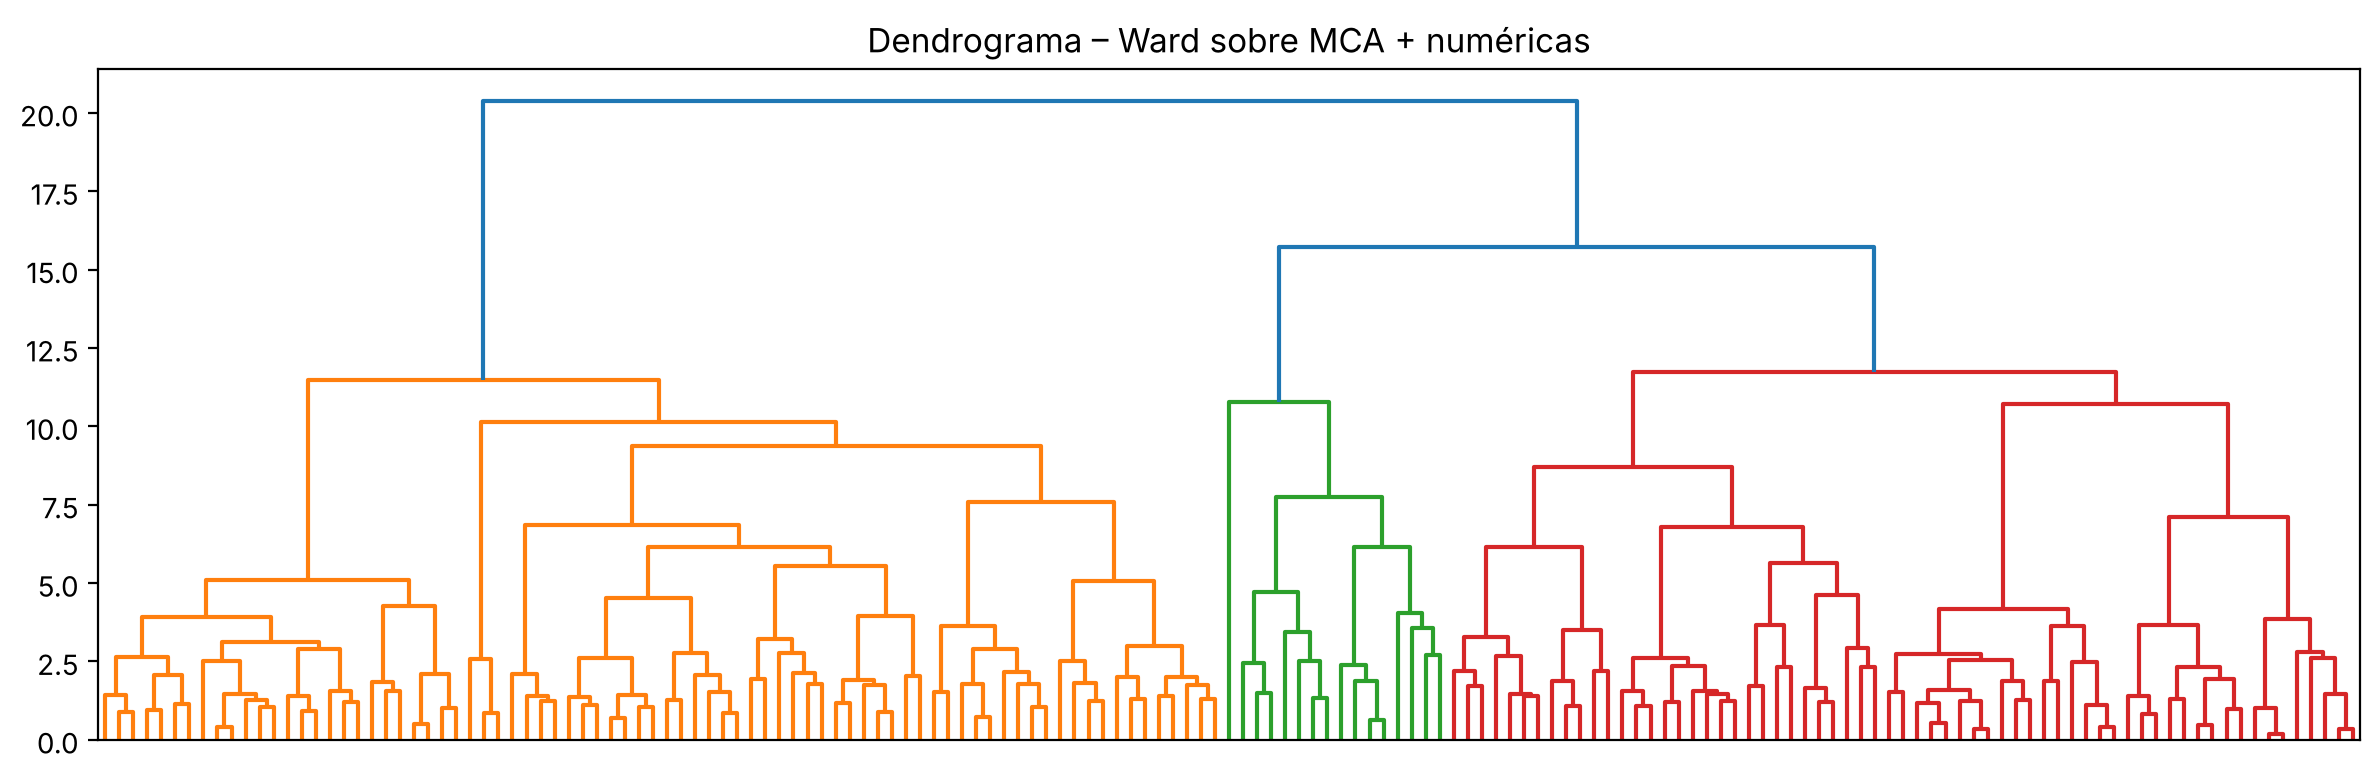

,modelo,silueta_euclidiana,silueta_gower,tamano_min,ARI_medio,ARI_sd,indice_combinado,candidato
k,,,,,,,,
2,Ward,0.159,0.124,80,0.619,0.153,0.098,False
3,Ward,0.179,0.134,16,0.631,0.164,0.113,True
4,Ward,0.153,0.125,16,0.497,0.151,0.076,True
5,Ward,0.106,0.067,16,0.398,0.099,0.042,True
6,Ward,0.112,0.061,1,0.401,0.101,0.045,False
7,Ward,0.115,0.047,1,0.411,0.094,0.047,False
8,Ward,0.132,0.035,1,0.428,0.077,0.056,False


In [5]:
plt.figure(figsize=(12, 4))
dendrogram(linkage(E, 'ward'), no_labels=True)
plt.title('Dendrograma – Ward sobre MCA + numéricas')
plt.tight_layout()
plt.show()
ajustar_ward = lambda M, k: AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(M)
t_ward = tabla_k('Ward', ajustar_ward)
t_ward.round(3)

# 6. Modelo 3 – Mezcla gaussiana (GMM)

Modelo probabilístico: cada grupo es una normal multivariada (con covarianza diagonal, por el tamaño de la muestra). Además de las métricas comunes se revisa el **BIC** (menor es mejor).

In [6]:
ajustar_gmm = lambda M, k: GaussianMixture(n_components=k, covariance_type='diag', n_init=5, random_state=42).fit(M).predict(M)
t_gmm = tabla_k('GMM', ajustar_gmm, extra=lambda k: {'BIC': GaussianMixture(n_components=k, covariance_type='diag', n_init=5, random_state=42).fit(E).bic(E)})
t_gmm.round(3)

,modelo,silueta_euclidiana,silueta_gower,tamano_min,ARI_medio,ARI_sd,BIC,indice_combinado,candidato
k,,,,,,,,,
2,GMM,0.183,0.160,68,0.730,0.358,3584.002,0.133,False
3,GMM,0.146,0.115,31,0.613,0.344,2956.519,0.090,True
4,GMM,0.113,0.110,28,0.422,0.169,2708.266,0.048,True
5,GMM,0.081,0.086,20,0.357,0.117,2711.300,0.029,True
6,GMM,0.055,0.048,5,0.499,0.309,1707.413,0.028,False
7,GMM,0.068,0.043,4,0.437,0.203,2386.829,0.030,False
8,GMM,0.010,-0.036,1,0.410,0.209,1512.051,0.004,False


**Comentario 6:** **La representación reducida no mejora la agrupación.**
- **K-Means:** siluetas euclidianas de 0.16 a 0.20, con estabilidad por debajo de 0.75 para k ≥ 3 (ARI de 0.49 a 0.73).
- **Ward:** tiene siluetas menores, y con k ≥ 6 genera grupos de 1 NNA.
- **GMM:** es el peor. Las siluetas caen hasta 0.01 al subir k, aparecen grupos de 1 a 5 NNA y el BIC baja de forma errática porque sobreajusta componentes casi vacías.
- **Medidas con Gower** (para comparar con la v1, que usa la misma información), las particiones de la v3 tienen siluetas de 0.04 a 0.16, **por debajo de la v1 (0.20)**.

# 7. Mejor modelo de la versión 3

In [7]:
modelos = {'K-Means': (t_km, ajustar_km), 'Ward': (t_ward, ajustar_ward), 'GMM': (t_gmm, ajustar_gmm)}
comp3 = []
for nombre, (t, f) in modelos.items():
    cand = t[t['candidato']]
    if len(cand):
        k = int(cand['indice_combinado'].idxmax())
        comp3.append(t.loc[k].to_dict() | {'modelo': nombre, 'k_elegido': k})
comp3 = pd.DataFrame(comp3).set_index('modelo')[['k_elegido', 'silueta_euclidiana', 'silueta_gower', 'tamano_min', 'ARI_medio', 'indice_combinado']]
MEJOR3 = comp3['indice_combinado'].idxmax()
K3 = int(comp3.loc[MEJOR3, 'k_elegido'])
lab3 = modelos[MEJOR3][1](E, K3)
X['cluster_v3'] = lab3
print(f'Mejor modelo v3: {MEJOR3} con k = {K3} | tamaños: {np.bincount(lab3).tolist()}')
comp3.round(3)

Mejor modelo v3: K-Means con k = 3 | tamaños: [61, 77, 23]


,k_elegido,silueta_euclidiana,silueta_gower,tamano_min,ARI_medio,indice_combinado
modelo,,,,,,
K-Means,3,0.195,0.139,23,0.732,0.143
Ward,3,0.179,0.134,16,0.631,0.113
GMM,3,0.146,0.115,31,0.613,0.090


In [8]:
pd.concat([X.groupby('cluster_v3')[['edad_anios', 'meses_permanencia', 'score_imc', 'prop_meses_sin_pti_vigente']].median().round(1),
           X.groupby('cluster_v3')[['malnutricion_flag', 'salud_fisica_cronica', 'provisional_prolongada']].mean().mul(100).round(0),
           (pd.crosstab(X['cluster_v3'], X['estado_pti'], normalize='index') * 100).round(0),
           (pd.crosstab(X['cluster_v3'], X['sexo'], normalize='index') * 100).round(0)], axis=1).T

cluster_v3,0,1,2
edad_anios,14.7,6.6,14.1
meses_permanencia,108.6,31.0,93.2
score_imc,0.0,1.0,1.0
prop_meses_sin_pti_vigente,0.8,0.7,0.9
malnutricion_flag,43.0,61.0,70.0
salud_fisica_cronica,10.0,9.0,43.0
provisional_prolongada,69.0,61.0,43.0
En tramite / Proceso,0.0,4.0,0.0
Sin PTI,20.0,16.0,35.0
Vencido,13.0,31.0,4.0


**Comentario 7:** El mejor modelo de la v3 es **K-Means con k = 3** (silueta 0.195, ARI 0.73, por debajo del umbral de 0.75). Sus grupos son básicamente **etapas de vida**: niños de ~6.6 años con 2.6 años en el CAR, adolescentes de ~14.7 años con 9 años en el CAR, y un grupo de adolescentes con más salud crónica (43 %). El PTI, la malnutrición y el sexo quedan casi iguales entre grupos. La causa está en la representación: las 8 variables cualitativas se resumieron en 3 columnas, mientras que las 5 numéricas conservan una columna cada una, así que **edad y permanencia dominan la distancia euclidiana**. La reducción por MCA es útil para **describir** la estructura cualitativa (Paso 4B), pero no para agrupar este caso.

# 8. Comparación de las tres versiones

Las siluetas de cada versión se calculan sobre distancias distintas: 13 variables en v1, 11 en v2 y un espacio euclidiano reducido en v3. Por eso no se comparan solas. Se usan cinco criterios:
1. **Separación y cohesión** dentro de su propia representación (silueta).
2. **Estabilidad** (ARI medio de remuestreo).
3. **Tamaño mínimo** de grupo, que tiene que ser operable para el equipo.
4. **Utilidad para el negocio:** qué tanto distinguen los perfiles las dos situaciones prolongadas del objetivo, la medida **provisional > 18 meses** y el **PTI no vigente** (V de Cramér, mayor es mejor).
5. **Independencia de lo demográfico:** asociación con el sexo y con el hogar. El documento pide no usar el hogar para segmentar, así que si los grupos solo reproducen el hogar, aportan poco.

In [9]:
asig = {}
for v in ['v1', 'v2']:
    ruta = RUTA / f'Clusters_{v}.xlsx'
    asig[v] = pd.read_excel(ruta, sheet_name='asignacion').set_index('id_persona')['cluster'].loc[X.index]
    comp_v = pd.read_excel(ruta, sheet_name='comparacion_modelos').set_index('modelo')
    asig[v + '_comp'] = comp_v
asig['v3'] = X['cluster_v3']

pti_no_vigente = (X['estado_pti'] != 'Vigente').astype(int)
final = []
for v in ['v1', 'v2', 'v3']:
    lab = asig[v]
    if v == 'v3':
        fila = comp3.loc[MEJOR3]
        modelo, k, sil, ari = MEJOR3, K3, fila['silueta_euclidiana'], fila['ARI_medio']
    else:
        cv = asig[v + '_comp']
        modelo = cv['indice_combinado'].idxmax()
        k, sil, ari = int(cv.loc[modelo, 'k_elegido']), cv.loc[modelo, 'silueta'], cv.loc[modelo, 'ARI_medio']
    final.append({'version': v, 'modelo': modelo, 'k': k, 'silueta (propia)': sil, 'silueta en Gower v1': silhouette_score(D_gower, lab, metric='precomputed'),
                  'ARI medio (estabilidad)': ari, 'tamaño mínimo': int(lab.value_counts().min()),
                  'V provisional>18m': cramer_v(lab, X['provisional_prolongada']), 'V PTI no vigente': cramer_v(lab, pti_no_vigente),
                  'V malnutrición': cramer_v(lab, X['malnutricion_flag']), 'V sexo': cramer_v(lab, X['sexo']), 'V hogar': cramer_v(lab, X['hogar'])})
final = pd.DataFrame(final).set_index('version')
print('ARI entre versiones:', {f'{a}-{b}': round(adjusted_rand_score(asig[a], asig[b]), 3) for a, b in [('v1', 'v2'), ('v1', 'v3'), ('v2', 'v3')]})
final.round(3)

ARI entre versiones: {'v1-v2': 0.423, 'v1-v3': 0.098, 'v2-v3': 0.069}


,modelo,k,silueta (propia),silueta en Gower v1,ARI medio (estabilidad),tamaño mínimo,V provisional>18m,V PTI no vigente,V malnutrición,V sexo,V hogar
version,,,,,,,,,,,
v1,PAM,5,0.203,0.203,0.824,26,0.542,0.866,0.639,0.610,0.395
v2,PAM,6,0.282,0.225,0.770,13,0.611,0.898,0.895,0.160,0.304
v3,K-Means,3,0.195,0.139,0.732,23,0.168,0.168,0.207,0.038,0.460


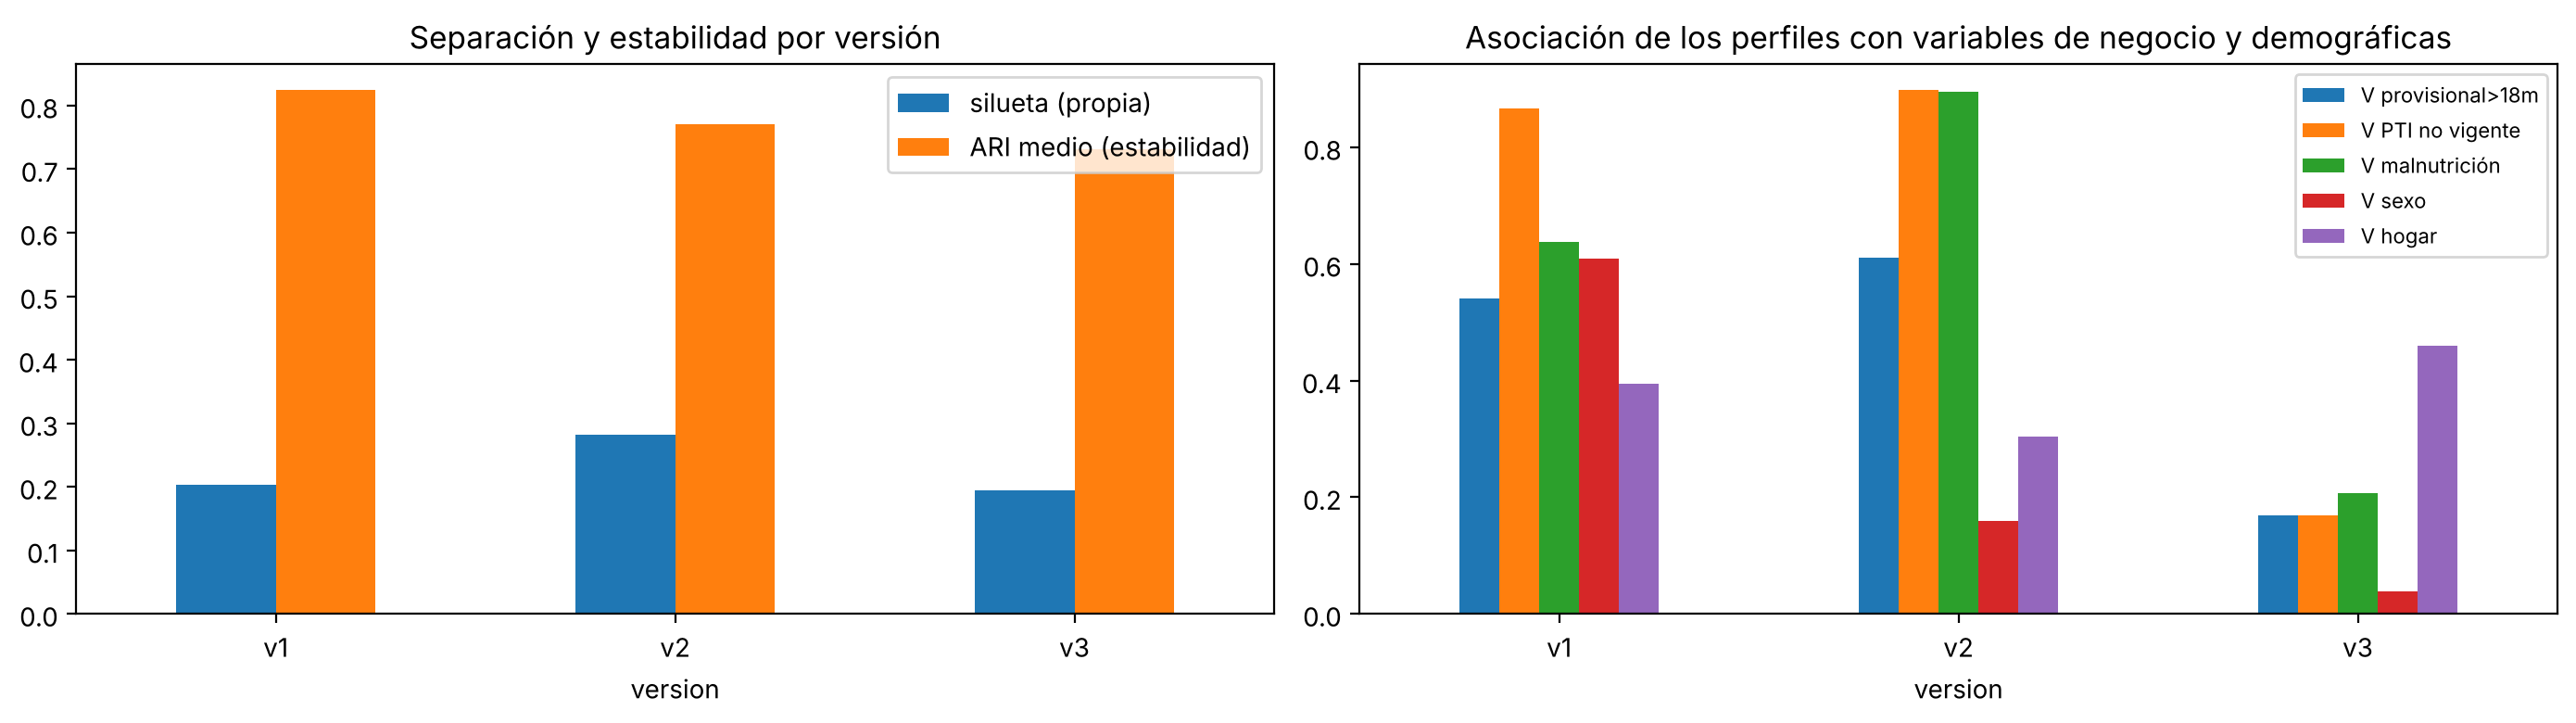

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
final[['silueta (propia)', 'ARI medio (estabilidad)']].plot.bar(ax=ax[0], rot=0)
ax[0].set_title('Separación y estabilidad por versión')
final[['V provisional>18m', 'V PTI no vigente', 'V malnutrición', 'V sexo', 'V hogar']].plot.bar(ax=ax[1], rot=0)
ax[1].set_title('Asociación de los perfiles con variables de negocio y demográficas')
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Comentario 8 – comparación.** De las tres versiones, la que mejor resultado da es la **v2: PAM (K-Medoids) sobre Gower con k = 6**:

| Criterio | v1 (PAM k=5) | **v2 (PAM k=6)** | v3 (K-Means k=3) |
|---|---|---|---|
| Silueta en su propia representación | 0.203 | **0.282** | 0.195 |
| Silueta medida con Gower de v1 (misma base) | 0.203 | **0.225** | 0.139 |
| Estabilidad (ARI medio) | **0.82** | 0.77 | 0.73 |
| Tamaño mínimo | 26 | 13 | 23 |
| Distingue la provisional > 18 meses (V) | 0.54 | **0.61** | 0.17 |
| Distingue el PTI no vigente (V) | 0.87 | **0.90** | 0.17 |
| Distingue la malnutrición (V) | 0.64 | **0.90** | 0.21 |
| Dependencia del sexo (V, menor es mejor) | 0.61 | 0.16 | 0.04 |
| Dependencia del hogar (V, menor es mejor) | 0.40 | **0.30** | 0.46 |

- La v2 tiene la **mejor separación**, incluso medida con la distancia de la v1, que la pone en desventaja.
- Es la que **mejor reconoce las situaciones prolongadas** del objetivo de negocio y no depende del sexo.
- Su estabilidad (0.77) es algo menor que la de la v1, pero está por encima del umbral de 0.75.
- La v3 casi no depende del sexo, pero tampoco reconoce ninguna situación de negocio y se alinea más con el hogar, porque agrupa por etapa de vida.
- Las tres versiones dan particiones distintas (ARI v1-v2 = 0.42; v3 con las demás < 0.10), lo que confirma que **la elección de variables y de representación importa más que el algoritmo**, y que el contraste de versiones era necesario.

**Limitaciones que hay que comunicar:** una silueta de 0.28 indica una estructura **débil a moderada**. Hay perfiles reconocibles y estables, pero los residentes cambian de forma gradual entre ellos. Con 161 NNA, los grupos chicos (perfil 2, con 13) deben validarse caso por caso con el equipo técnico, como plantea el objetivo de negocio.

Después de esta comparación se probó la v4 (la v2 sin el nivel de atención en salud mental). La validación de las cuatro versiones y la elección final están en el Paso 8.

# 9. Guardado

In [11]:
salida = X[['id_original', 'cluster_v3'] + list(TIPOS)].rename(columns={'cluster_v3': 'cluster'})
with pd.ExcelWriter(RUTA / f'Clusters_{VERSION}.xlsx') as w:
    salida.reset_index().to_excel(w, sheet_name='asignacion', index=False)
    pd.concat([t_km, t_ward, t_gmm]).reset_index().to_excel(w, sheet_name='metricas_por_k', index=False)
    comp3.reset_index().to_excel(w, sheet_name='comparacion_modelos', index=False)
    final.reset_index().to_excel(w, sheet_name='comparacion_versiones', index=False)
print('Guardado:', (RUTA / f'Clusters_{VERSION}.xlsx').relative_to(BASE))

Guardado: Resultados_EnfoqueB/Clusters_v3.xlsx


**Comentario 9:** La asignación de la v3 y sus métricas se guardan en `Resultados_EnfoqueB/Clusters_v3.xlsx`, igual que en las otras versiones. El Paso 8 lee este archivo.